# Simplified Checkout A/B Test: Design and Simulation

> **SIMULATED EXPERIMENT DATA ONLY**
>
> No experiment was run. Historical GA4 aggregates are used only to
> plan a test. Every row generated later in this notebook has
> `is_simulated = True`.

**Decision question:** Should a simplified checkout replace the current
experience for eligible users?

This notebook locks a planning design, quantifies the sample-size and
duration trade-off, and demonstrates the pre-registered analysis on one
seeded synthetic experiment. A favorable simulated result is not
evidence that the product change works.

## 1. Load governed planning aggregates

SQL remains the source of truth. The notebook selects the newest
complete aggregate export and never loads raw users, sessions, events,
transactions, or browsing paths.

In [1]:
%matplotlib inline

from pathlib import Path
from math import ceil, erfc, floor, sqrt
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
RESULT_ROOT = ROOT / "data" / "interim" / "query_results"
FIGURE_DIR = ROOT / "notebooks" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_FILES = [
    "01_metric_tree_summary.csv",
    "05_checkout_funnel.csv",
]
complete_exports = [
    path
    for path in RESULT_ROOT.iterdir()
    if path.is_dir()
    and all((path / filename).is_file() for filename in REQUIRED_FILES)
]
if not complete_exports:
    raise FileNotFoundError(
        "No complete aggregate export found. Run `make extract` first."
    )
EXPORT_DIR = sorted(complete_exports)[-1]

summary = pd.read_csv(
    EXPORT_DIR / "01_metric_tree_summary.csv"
).iloc[0]
checkout = pd.read_csv(EXPORT_DIR / "05_checkout_funnel.csv")

datasets = {
    "summary": pd.DataFrame([summary]),
    "checkout": checkout,
}
forbidden_identifier_columns = {
    "user_key",
    "session_key",
    "event_timestamp",
    "order_key",
    "transaction_id",
}
for name, frame in datasets.items():
    leaked = forbidden_identifier_columns.intersection(frame.columns)
    assert not leaked, f"{name} contains prohibited identifiers: {leaked}"

checkout_sessions = int(
    checkout.loc[
        checkout["stage_name"] == "begin_checkout", "sessions"
    ].iloc[0]
)
purchase_after_checkout_sessions = int(
    checkout["purchase_after_checkout_sessions"].iloc[0]
)
historical_baseline_proxy = (
    purchase_after_checkout_sessions / checkout_sessions
)
observed_days = int(summary["observed_calendar_days"])
average_order_value = float(summary["average_order_value_usd"])
daily_checkout_session_proxy = checkout_sessions / observed_days

assert checkout_sessions == 5_187
assert purchase_after_checkout_sessions == 2_491
assert observed_days == 92
assert abs(historical_baseline_proxy - 0.4802390591864276) < 1e-12

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
NAVY = "#17324D"
BLUE = "#2C7FB8"
TEAL = "#2A9D8F"
ORANGE = "#F4A261"
RED = "#D95F59"
GREY = "#7A8793"

print(f"Aggregate export: {EXPORT_DIR.name}")
print(
    f"Planning proxy: {purchase_after_checkout_sessions:,} / "
    f"{checkout_sessions:,} = {historical_baseline_proxy:.2%}"
)

Aggregate export: 20260731T052813Z
Planning proxy: 2,491 / 5,187 = 48.02%


## 2. Metric contract and historical baseline proxy

The historical rate is a **same-session checkout-session rate**. The
planned experiment uses a **user-randomized 24-hour outcome**. The
historical value is therefore a planning proxy, not a guaranteed
production baseline.

Follow-up aggregate query `11_checkout_telemetry_diagnostic.sql`
reconciles the historical paths and shows that all 941 purchases outside
the strict intermediate sequence contain shipping at or before the
governed checkout start and payment before purchase. Repeated checkout
entry—not missing all intermediate telemetry—creates the strict gap.

In [2]:
Z_95 = NormalDist().inv_cdf(0.975)

def wilson_interval(successes, trials, z=Z_95):
    successes = int(successes)
    trials = int(trials)
    if trials == 0:
        return (np.nan, np.nan)
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    center = (
        proportion + z**2 / (2 * trials)
    ) / denominator
    half_width = (
        z
        * sqrt(
            proportion * (1 - proportion) / trials
            + z**2 / (4 * trials**2)
        )
        / denominator
    )
    return max(0, center - half_width), min(1, center + half_width)

baseline_lower, baseline_upper = wilson_interval(
    purchase_after_checkout_sessions,
    checkout_sessions,
)
baseline_table = pd.DataFrame(
    [
        {
            "Planning input": "Ordered checkout sessions",
            "Value": f"{checkout_sessions:,}",
            "Use": "Eligibility-volume proxy",
        },
        {
            "Planning input": "Purchases after ordered checkout",
            "Value": f"{purchase_after_checkout_sessions:,}",
            "Use": "Primary-rate numerator proxy",
        },
        {
            "Planning input": "Historical completion proxy",
            "Value": f"{historical_baseline_proxy:.2%}",
            "Use": "Sample-size baseline",
        },
        {
            "Planning input": "95% Wilson interval",
            "Value": (
                f"{baseline_lower:.2%}–{baseline_upper:.2%}"
            ),
            "Use": "Baseline uncertainty sensitivity",
        },
        {
            "Planning input": "Checkout-session volume",
            "Value": f"{daily_checkout_session_proxy:.1f}/day",
            "Use": "Duration proxy only",
        },
        {
            "Planning input": "Clean historical AOV",
            "Value": f"${average_order_value:,.2f}",
            "Use": "Revenue scenario only",
        },
    ]
)
display(baseline_table)

,Planning input,Value,Use
0,Ordered checkout sessions,"5,187",Eligibility-volume proxy
1,Purchases after ordered checkout,"2,491",Primary-rate numerator proxy
2,Historical completion proxy,48.02%,Sample-size baseline
3,95% Wilson interval,46.67%–49.38%,Baseline uncertainty sensitivity
4,Checkout-session volume,56.4/day,Duration proxy only
5,Clean historical AOV,$69.13,Revenue scenario only


## 3. Pre-registration contract

| Design item | Locked planning definition |
|---|---|
| Control | Current checkout |
| Treatment | One streamlined checkout page combining shipping and payment, removing nonessential optional fields while preserving price, shipping, tax, and order-summary disclosure |
| Eligibility | First qualifying `begin_checkout`; assignment is recorded once by a dedicated sticky experiment-exposure event |
| Randomization unit | Pseudonymous user, sticky 50/50 assignment |
| Analysis population | Intention to treat: every assigned eligible user |
| Primary outcome | Clean purchase within 24 hours of first eligible exposure |
| Primary estimand | Treatment minus control conversion, in percentage points |
| Secondary outcome | Gross purchase revenue per eligible assigned user |
| Guardrails | Payment-error rate, refund/cancellation rate, and checkout time after telemetry validation |
| Significance | Two-sided 5% |
| Target power | 80% |
| Planning MDE | +5.00 percentage points absolute |
| SRM gate | Stop interpretation and investigate if allocation-test p-value is below 0.001 |
| Peeking | None; analyze after the target sample at the end of a full week |
| Subgroups | New versus Returning is secondary and exploratory; no primary subgroup claim |

The +5.00 pp planning MDE is a **provisional product assumption**. It is
a 10.4% relative lift over the proxy baseline and must be confirmed as
the smallest effect worth shipping before a real launch. It was not
selected from an observed treatment result.

## 4. Sample size and MDE sensitivity

The calculation uses the standard equal-allocation normal approximation
for two independent proportions. It is a planning calculation, not an
outcome test.

,Absolute MDE,Relative lift,Per arm,Total,Proxy weeks,Historical-window scenario orders,Historical-window scenario revenue
0,0.50 pp,1.0%,"156,790","313,580",794.6,25.9,"$1,793"
1,1.00 pp,2.1%,"39,210","78,420",198.7,51.9,"$3,586"
2,2.00 pp,4.2%,"9,807","19,614",49.7,103.7,"$7,172"
3,3.00 pp,6.2%,"4,359","8,718",22.1,155.6,"$10,758"
4,4.00 pp,8.3%,"2,452","4,904",12.4,207.5,"$14,344"
5,5.00 pp,10.4%,"1,569","3,138",8.0,259.4,"$17,930"


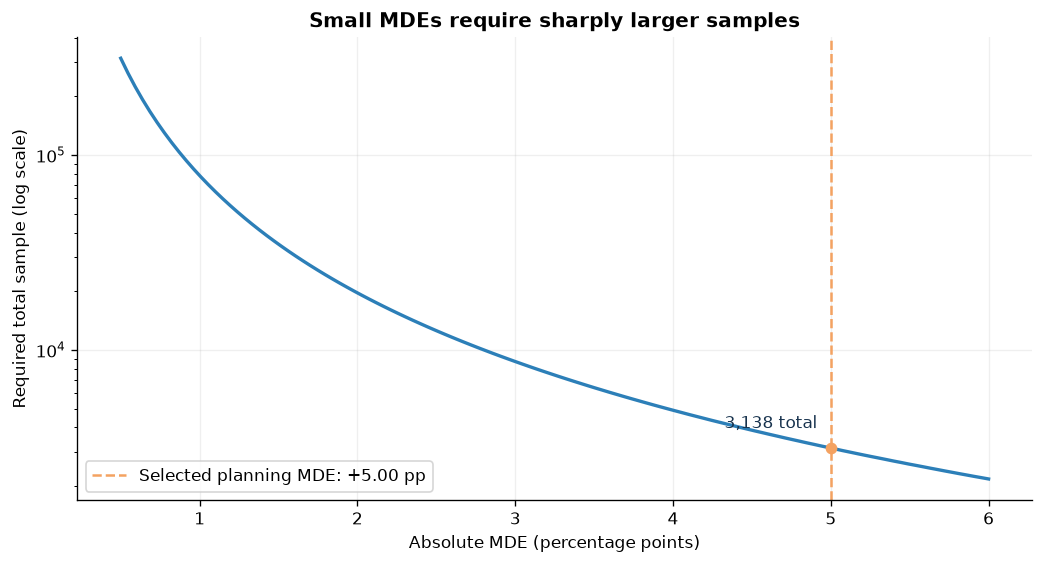

In [3]:
ALPHA = 0.05
TARGET_POWER = 0.80
PLANNED_MDE = 0.05
OPERATIONAL_BUFFER = 0.05

def sample_size_per_arm(
    baseline,
    absolute_mde,
    alpha=ALPHA,
    power=TARGET_POWER,
):
    treatment = baseline + absolute_mde
    if not 0 < baseline < 1 or not 0 < treatment < 1:
        raise ValueError("Baseline and treatment rates must be in (0, 1).")
    z_alpha = NormalDist().inv_cdf(1 - alpha / 2)
    z_power = NormalDist().inv_cdf(power)
    pooled_midpoint = (baseline + treatment) / 2
    numerator = (
        z_alpha
        * sqrt(
            2
            * pooled_midpoint
            * (1 - pooled_midpoint)
        )
        + z_power
        * sqrt(
            baseline * (1 - baseline)
            + treatment * (1 - treatment)
        )
    ) ** 2
    return ceil(numerator / absolute_mde**2)

mde_values = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]
sample_size_rows = []
for mde in mde_values:
    per_arm = sample_size_per_arm(
        historical_baseline_proxy,
        mde,
    )
    total = 2 * per_arm
    expected_days = total / daily_checkout_session_proxy
    sample_size_rows.append(
        {
            "Absolute MDE": mde,
            "Relative lift": mde / historical_baseline_proxy,
            "Per arm": per_arm,
            "Total": total,
            "Proxy weeks": expected_days / 7,
            "Historical-window scenario orders": (
                checkout_sessions * mde
            ),
            "Historical-window scenario revenue": (
                checkout_sessions * mde * average_order_value
            ),
        }
    )

sample_size_grid = pd.DataFrame(sample_size_rows)
sample_size_display = sample_size_grid.copy()
sample_size_display["Absolute MDE"] = sample_size_display[
    "Absolute MDE"
].map(lambda value: f"{value * 100:.2f} pp")
sample_size_display["Relative lift"] = sample_size_display[
    "Relative lift"
].map(lambda value: f"{value:.1%}")
for column in ["Per arm", "Total"]:
    sample_size_display[column] = sample_size_display[column].map(
        lambda value: f"{int(value):,}"
    )
sample_size_display["Proxy weeks"] = sample_size_display[
    "Proxy weeks"
].map(lambda value: f"{value:,.1f}")
sample_size_display["Historical-window scenario orders"] = (
    sample_size_display[
        "Historical-window scenario orders"
    ].map(lambda value: f"{value:,.1f}")
)
sample_size_display["Historical-window scenario revenue"] = (
    sample_size_display[
        "Historical-window scenario revenue"
    ].map(lambda value: f"${value:,.0f}")
)
display(sample_size_display)

core_n_per_arm = sample_size_per_arm(
    historical_baseline_proxy,
    PLANNED_MDE,
)
target_n_per_arm = ceil(
    core_n_per_arm * (1 + OPERATIONAL_BUFFER)
)
target_total = 2 * target_n_per_arm
proxy_duration_days = target_total / daily_checkout_session_proxy
proxy_duration_weeks = proxy_duration_days / 7

assert core_n_per_arm == 1_569
assert target_n_per_arm == 1_648
assert target_total == 3_296

curve_mde = np.linspace(0.005, 0.06, 120)
curve_total = np.array(
    [
        2
        * sample_size_per_arm(
            historical_baseline_proxy,
            value,
        )
        for value in curve_mde
    ]
)
fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.plot(curve_mde * 100, curve_total, color=BLUE, linewidth=2)
ax.axvline(
    PLANNED_MDE * 100,
    color=ORANGE,
    linestyle="--",
    label="Selected planning MDE: +5.00 pp",
)
ax.scatter(
    [PLANNED_MDE * 100],
    [2 * core_n_per_arm],
    color=ORANGE,
    zorder=3,
)
ax.annotate(
    f"{2 * core_n_per_arm:,} total",
    (PLANNED_MDE * 100, 2 * core_n_per_arm),
    xytext=(-8, 12),
    textcoords="offset points",
    ha="right",
    color=NAVY,
)
ax.set_yscale("log")
ax.set_xlabel("Absolute MDE (percentage points)")
ax.set_ylabel("Required total sample (log scale)")
ax.set_title("Small MDEs require sharply larger samples")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "06_sample_size_curve.png",
    bbox_inches="tight",
)
plt.show()

In [4]:
baseline_sensitivity = pd.DataFrame(
    [
        {
            "Baseline assumption": "Wilson lower bound",
            "Baseline rate": baseline_lower,
            "Per-arm N at +5 pp": sample_size_per_arm(
                baseline_lower,
                PLANNED_MDE,
            ),
        },
        {
            "Baseline assumption": "Historical point estimate",
            "Baseline rate": historical_baseline_proxy,
            "Per-arm N at +5 pp": core_n_per_arm,
        },
        {
            "Baseline assumption": "Wilson upper bound",
            "Baseline rate": baseline_upper,
            "Per-arm N at +5 pp": sample_size_per_arm(
                baseline_upper,
                PLANNED_MDE,
            ),
        },
    ]
)
baseline_sensitivity_display = baseline_sensitivity.copy()
baseline_sensitivity_display["Baseline rate"] = (
    baseline_sensitivity_display["Baseline rate"].map(
        lambda value: f"{value:.2%}"
    )
)
baseline_sensitivity_display["Per-arm N at +5 pp"] = (
    baseline_sensitivity_display["Per-arm N at +5 pp"].map(
        lambda value: f"{int(value):,}"
    )
)
display(baseline_sensitivity_display)

print(
    f"Core statistical sample: {core_n_per_arm:,} per arm "
    f"({2 * core_n_per_arm:,} total)."
)
print(
    f"With a 5% operational buffer: {target_n_per_arm:,} per arm "
    f"({target_total:,} total)."
)
print(
    f"Session-volume proxy duration: {proxy_duration_weeks:.2f} weeks."
)

,Baseline assumption,Baseline rate,Per-arm N at +5 pp
0,Wilson lower bound,46.67%,"1,569"
1,Historical point estimate,48.02%,"1,569"
2,Wilson upper bound,49.38%,"1,567"


Core statistical sample: 1,569 per arm (3,138 total).
With a 5% operational buffer: 1,648 per arm (3,296 total).
Session-volume proxy duration: 8.35 weeks.


The earlier +0.50 pp opportunity scenario is not a feasible MDE at the
observed traffic proxy: it would require approximately 313,580 eligible
users in total, or about 795 proxy weeks. Opportunity sizing and
experiment detectability answer different questions.

## 5. Fixed-duration MDE

The next table reverses the calculation: if the test is limited to a
fixed number of weeks, what absolute lift is detectable? The throughput
uses historical **checkout sessions**, not deduplicated eligible users,
so it is optimistic until a shadow assignment validates current
user-level traffic.

,Weeks,Proxy total eligible units,Proxy units per arm,Fixed-N MDE
0,4,"1,578",789,7.04 pp
1,6,"2,367","1,183",5.76 pp
2,8,"3,157","1,578",4.98 pp
3,12,"4,735","2,367",4.07 pp
4,16,"6,314","3,157",3.53 pp
5,24,"9,471","4,735",2.88 pp


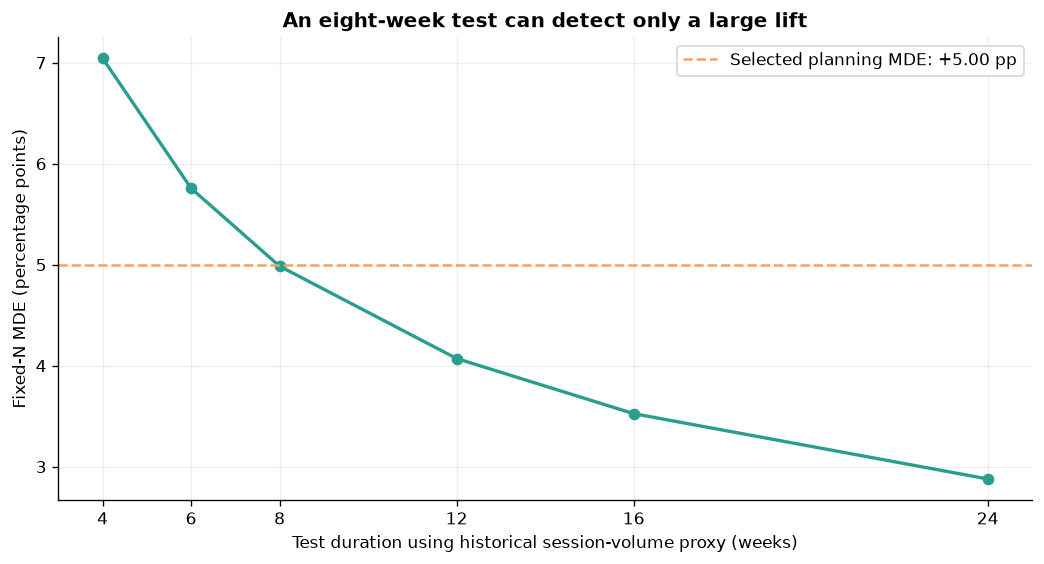

In [5]:
def fixed_n_mde(baseline, n_per_arm):
    lower = 1e-6
    upper = min(0.25, 1 - baseline - 1e-6)
    for _ in range(80):
        midpoint = (lower + upper) / 2
        if sample_size_per_arm(baseline, midpoint) <= n_per_arm:
            upper = midpoint
        else:
            lower = midpoint
    return upper

duration_weeks = [4, 6, 8, 12, 16, 24]
duration_rows = []
for weeks in duration_weeks:
    proxy_total = floor(
        daily_checkout_session_proxy * 7 * weeks
    )
    proxy_per_arm = floor(proxy_total / 2)
    duration_rows.append(
        {
            "Weeks": weeks,
            "Proxy total eligible units": proxy_total,
            "Proxy units per arm": proxy_per_arm,
            "Fixed-N MDE": fixed_n_mde(
                historical_baseline_proxy,
                proxy_per_arm,
            ),
        }
    )
duration_sensitivity = pd.DataFrame(duration_rows)
duration_display = duration_sensitivity.copy()
for column in [
    "Proxy total eligible units",
    "Proxy units per arm",
]:
    duration_display[column] = duration_display[column].map(
        lambda value: f"{int(value):,}"
    )
duration_display["Fixed-N MDE"] = duration_display[
    "Fixed-N MDE"
].map(lambda value: f"{value * 100:.2f} pp")
display(duration_display)

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.plot(
    duration_sensitivity["Weeks"],
    duration_sensitivity["Fixed-N MDE"] * 100,
    marker="o",
    color=TEAL,
    linewidth=2,
)
ax.axhline(
    PLANNED_MDE * 100,
    color=ORANGE,
    linestyle="--",
    label="Selected planning MDE: +5.00 pp",
)
ax.set_xticks(duration_weeks)
ax.set_xlabel("Test duration using historical session-volume proxy (weeks)")
ax.set_ylabel("Fixed-N MDE (percentage points)")
ax.set_title("An eight-week test can detect only a large lift")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "07_duration_mde.png",
    bbox_inches="tight",
)
plt.show()

In [6]:
display(
    Markdown(
        f"""
        ### Planning implication

        - **Selected planning MDE:** +{PLANNED_MDE * 100:.2f} pp
          ({PLANNED_MDE / historical_baseline_proxy:.1%} relative).
        - **Core sample:** {core_n_per_arm:,} per arm.
        - **Buffered enrollment target:** {target_n_per_arm:,} per arm,
          {target_total:,} total.
        - **Historical session-volume proxy:** approximately
          {proxy_duration_weeks:.1f} weeks.
        - **Operational stopping rule:** reach the buffered sample and
          stop only at the end of a full week, with no outcome peeking.

        A real duration forecast must replace checkout sessions with
        current unique eligible users per day.
        """
    )
)


        ### Planning implication

        - **Selected planning MDE:** +5.00 pp
          (10.4% relative).
        - **Core sample:** 1,569 per arm.
        - **Buffered enrollment target:** 1,648 per arm,
          3,296 total.
        - **Historical session-volume proxy:** approximately
          8.4 weeks.
        - **Operational stopping rule:** reach the buffered sample and
          stop only at the end of a full week, with no outcome peeking.

        A real duration forecast must replace checkout sessions with
        current unique eligible users per day.
        

## 6. Generate one seeded synthetic experiment

> **Everything below is simulated.**

The data-generating process assumes the treatment's true conversion is
exactly 5.00 pp above control. The realized estimate will differ because
of sampling noise. Revenue and payment-error fields are also synthetic.
No synthetic row is saved as observed GA4 data.

In [7]:
SIMULATION_SEED = 20_260_731
TRUE_SIMULATED_LIFT = PLANNED_MDE
SIMULATED_PAYMENT_ERROR_RATE = 0.04
PAYMENT_ERROR_MARGIN = 0.015

rng = np.random.default_rng(SIMULATION_SEED)
simulated = pd.DataFrame(
    {
        "synthetic_unit_id": [
            f"SIM-{index:06d}"
            for index in range(1, target_total + 1)
        ],
        "variant": rng.choice(
            ["control", "treatment"],
            size=target_total,
            p=[0.5, 0.5],
        ),
    }
)
conversion_probability = np.where(
    simulated["variant"].eq("treatment"),
    historical_baseline_proxy + TRUE_SIMULATED_LIFT,
    historical_baseline_proxy,
)
simulated["converted_within_24h"] = rng.binomial(
    1,
    conversion_probability,
).astype(bool)
simulated_order_value = rng.gamma(
    shape=4,
    scale=average_order_value / 4,
    size=target_total,
)
simulated["purchase_revenue_usd"] = np.where(
    simulated["converted_within_24h"],
    simulated_order_value,
    0.0,
)
simulated["payment_error"] = rng.binomial(
    1,
    SIMULATED_PAYMENT_ERROR_RATE,
    size=target_total,
).astype(bool)
simulated["assignment_probability"] = 0.5
simulated["is_simulated"] = True

assert len(simulated) == target_total
assert simulated["synthetic_unit_id"].is_unique
assert simulated["is_simulated"].all()
assert set(simulated["variant"]) == {"control", "treatment"}
assert (
    simulated.loc[
        ~simulated["converted_within_24h"],
        "purchase_revenue_usd",
    ]
    == 0
).all()

print(
    "SIMULATED DATA ONLY — these rows are not observed GA4 users "
    "or experiment results."
)
display(simulated.head(8))

SIMULATED DATA ONLY — these rows are not observed GA4 users or experiment results.


,synthetic_unit_id,variant,converted_within_24h,purchase_revenue_usd,payment_error,assignment_probability,is_simulated
0,SIM-000001,treatment,True,32.4573,False,0.5000,True
1,SIM-000002,control,True,49.5688,False,0.5000,True
2,SIM-000003,control,False,0.0000,False,0.5000,True
3,SIM-000004,control,True,88.4551,False,0.5000,True
4,SIM-000005,treatment,False,0.0000,False,0.5000,True
5,SIM-000006,treatment,True,39.2218,False,0.5000,True
6,SIM-000007,control,True,92.4108,False,0.5000,True
7,SIM-000008,treatment,False,0.0000,False,0.5000,True


## 7. Assignment integrity: sample-ratio mismatch

SRM is checked before outcomes. A p-value below 0.001 blocks
interpretation and triggers an investigation of assignment, eligibility,
and logging.

In [8]:
observed_assignment = (
    simulated["variant"]
    .value_counts()
    .reindex(["control", "treatment"])
)
expected_assignment = pd.Series(
    target_total / 2,
    index=["control", "treatment"],
)
srm_chi_square = (
    (observed_assignment - expected_assignment) ** 2
    / expected_assignment
).sum()
srm_p_value = erfc(sqrt(srm_chi_square / 2))
srm_pass = srm_p_value >= 0.001

srm_table = pd.DataFrame(
    {
        "Variant": ["control", "treatment"],
        "Observed": observed_assignment.values,
        "Expected": expected_assignment.values,
    }
)
srm_table["Observed share"] = (
    srm_table["Observed"] / target_total
).map(lambda value: f"{value:.2%}")
display(srm_table)
print(
    f"SRM chi-square = {srm_chi_square:.3f}; "
    f"p = {srm_p_value:.4f}; gate pass = {srm_pass}."
)
assert srm_pass

,Variant,Observed,Expected,Observed share
0,control,1617,"1,648.0000",49.06%
1,treatment,1679,"1,648.0000",50.94%


SRM chi-square = 1.166; p = 0.2802; gate pass = True.


## 8. Primary conversion analysis

The treatment-minus-control interval uses Newcombe's Wilson-score
method. The p-value is the conventional pooled two-proportion z-test.
The confidence interval is the primary uncertainty statement.

,variant,assigned_users,converted_users,conversion_rate,ci95_lower,ci95_upper
0,control,1617,779,48.18%,45.75%,50.61%
1,treatment,1679,923,54.97%,52.58%,57.34%


,Estimand,Estimate,95% CI,Relative lift,Two-sided p-value
0,Treatment − control conversion,+6.80 pp,+3.39 to +10.19 pp,+14.1%,0.00009


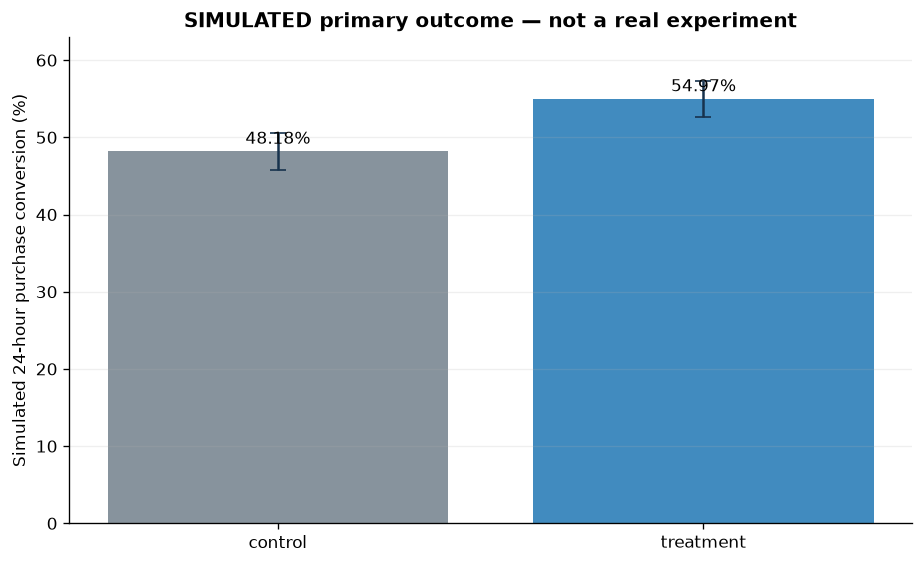

In [9]:
def newcombe_difference(x1, n1, x2, n2):
    p1 = x1 / n1
    p2 = x2 / n2
    lower1, upper1 = wilson_interval(x1, n1)
    lower2, upper2 = wilson_interval(x2, n2)
    difference = p1 - p2
    lower = difference - sqrt(
        (p1 - lower1) ** 2 + (upper2 - p2) ** 2
    )
    upper = difference + sqrt(
        (upper1 - p1) ** 2 + (p2 - lower2) ** 2
    )
    return difference, max(-1, lower), min(1, upper)

def two_proportion_z_test(x1, n1, x2, n2):
    p1 = x1 / n1
    p2 = x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    standard_error = sqrt(
        pooled
        * (1 - pooled)
        * (1 / n1 + 1 / n2)
    )
    z_statistic = (p1 - p2) / standard_error
    p_value = 2 * (
        1 - NormalDist().cdf(abs(z_statistic))
    )
    return z_statistic, p_value

primary_summary = (
    simulated.groupby("variant", as_index=False)
    .agg(
        assigned_users=("synthetic_unit_id", "count"),
        converted_users=("converted_within_24h", "sum"),
    )
)
primary_summary["conversion_rate"] = (
    primary_summary["converted_users"]
    / primary_summary["assigned_users"]
)
interval_rows = []
for row in primary_summary.itertuples():
    lower, upper = wilson_interval(
        row.converted_users,
        row.assigned_users,
    )
    interval_rows.append((lower, upper))
primary_summary["ci95_lower"] = [
    value[0] for value in interval_rows
]
primary_summary["ci95_upper"] = [
    value[1] for value in interval_rows
]

control_row = primary_summary.loc[
    primary_summary["variant"] == "control"
].iloc[0]
treatment_row = primary_summary.loc[
    primary_summary["variant"] == "treatment"
].iloc[0]
effect, effect_lower, effect_upper = newcombe_difference(
    int(treatment_row["converted_users"]),
    int(treatment_row["assigned_users"]),
    int(control_row["converted_users"]),
    int(control_row["assigned_users"]),
)
z_statistic, primary_p_value = two_proportion_z_test(
    int(treatment_row["converted_users"]),
    int(treatment_row["assigned_users"]),
    int(control_row["converted_users"]),
    int(control_row["assigned_users"]),
)
relative_lift = effect / control_row["conversion_rate"]

primary_display = primary_summary.copy()
for column in [
    "conversion_rate",
    "ci95_lower",
    "ci95_upper",
]:
    primary_display[column] = primary_display[column].map(
        lambda value: f"{value:.2%}"
    )
display(primary_display)

effect_table = pd.DataFrame(
    [
        {
            "Estimand": "Treatment − control conversion",
            "Estimate": f"{effect * 100:+.2f} pp",
            "95% CI": (
                f"{effect_lower * 100:+.2f} to "
                f"{effect_upper * 100:+.2f} pp"
            ),
            "Relative lift": f"{relative_lift:+.1%}",
            "Two-sided p-value": f"{primary_p_value:.5f}",
        }
    ]
)
display(effect_table)

fig, ax = plt.subplots(figsize=(7.8, 4.8))
rates = primary_summary["conversion_rate"] * 100
lower_error = (
    primary_summary["conversion_rate"]
    - primary_summary["ci95_lower"]
) * 100
upper_error = (
    primary_summary["ci95_upper"]
    - primary_summary["conversion_rate"]
) * 100
bars = ax.bar(
    primary_summary["variant"],
    rates,
    color=[GREY, BLUE],
    alpha=0.9,
)
ax.errorbar(
    primary_summary["variant"],
    rates,
    yerr=[lower_error, upper_error],
    fmt="none",
    ecolor=NAVY,
    capsize=5,
)
ax.set_ylabel("Simulated 24-hour purchase conversion (%)")
ax.set_title("SIMULATED primary outcome — not a real experiment")
ax.grid(axis="y", alpha=0.2)
for bar, value in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1.0,
        f"{value:.2f}%",
        ha="center",
    )
ax.set_ylim(0, max(rates) + 8)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "08_simulated_primary_effect.png",
    bbox_inches="tight",
)
plt.show()

## 9. Secondary revenue and simulated payment-error guardrail

Revenue per eligible user is analyzed without conditioning on purchase.
Its interval uses a large-sample difference in means. The payment-error
non-inferiority margin of +1.50 pp is **illustrative** and requires
payments/engineering approval before a real pre-registration.

In [10]:
control_revenue = simulated.loc[
    simulated["variant"] == "control",
    "purchase_revenue_usd",
]
treatment_revenue = simulated.loc[
    simulated["variant"] == "treatment",
    "purchase_revenue_usd",
]
revenue_effect = (
    treatment_revenue.mean() - control_revenue.mean()
)
revenue_standard_error = sqrt(
    treatment_revenue.var(ddof=1) / len(treatment_revenue)
    + control_revenue.var(ddof=1) / len(control_revenue)
)
revenue_lower = revenue_effect - Z_95 * revenue_standard_error
revenue_upper = revenue_effect + Z_95 * revenue_standard_error

payment_summary = (
    simulated.groupby("variant", as_index=False)
    .agg(
        assigned_users=("synthetic_unit_id", "count"),
        payment_errors=("payment_error", "sum"),
    )
)
payment_summary["payment_error_rate"] = (
    payment_summary["payment_errors"]
    / payment_summary["assigned_users"]
)
control_payment = payment_summary.loc[
    payment_summary["variant"] == "control"
].iloc[0]
treatment_payment = payment_summary.loc[
    payment_summary["variant"] == "treatment"
].iloc[0]
(
    payment_effect,
    payment_lower,
    payment_upper,
) = newcombe_difference(
    int(treatment_payment["payment_errors"]),
    int(treatment_payment["assigned_users"]),
    int(control_payment["payment_errors"]),
    int(control_payment["assigned_users"]),
)
payment_guardrail_pass = (
    payment_upper < PAYMENT_ERROR_MARGIN
)

secondary_results = pd.DataFrame(
    [
        {
            "Metric": "Revenue per eligible user",
            "Treatment": f"${treatment_revenue.mean():.2f}",
            "Control": f"${control_revenue.mean():.2f}",
            "Difference": f"${revenue_effect:+.2f}",
            "95% CI": (
                f"${revenue_lower:+.2f} to "
                f"${revenue_upper:+.2f}"
            ),
            "Demo gate": "Secondary; no automatic ship rule",
        },
        {
            "Metric": "Payment-error rate",
            "Treatment": (
                f"{treatment_payment['payment_error_rate']:.2%}"
            ),
            "Control": (
                f"{control_payment['payment_error_rate']:.2%}"
            ),
            "Difference": f"{payment_effect * 100:+.2f} pp",
            "95% CI": (
                f"{payment_lower * 100:+.2f} to "
                f"{payment_upper * 100:+.2f} pp"
            ),
            "Demo gate": (
                f"Upper CI < +{PAYMENT_ERROR_MARGIN * 100:.2f} pp: "
                f"{payment_guardrail_pass}"
            ),
        },
    ]
)
display(secondary_results)

,Metric,Treatment,Control,Difference,95% CI,Demo gate
0,Revenue per eligible user,$38.05,$33.25,$+4.80,$+1.88 to $+7.73,Secondary; no automatic ship rule
1,Payment-error rate,4.05%,4.08%,-0.03 pp,-1.40 to +1.33 pp,Upper CI < +1.50 pp: True


## 10. A/A calibration and power simulation

One synthetic result can be unusually favorable or unfavorable. The
repeated simulation checks whether the planned test has approximately
5% false positives under no effect and 80% power when the true effect
equals the selected MDE.

,Scenario,Rejection rate,Target
0,A/A: true lift = 0,4.98%,5.00%
1,A/B: true lift = selected MDE,80.46%,80.00%


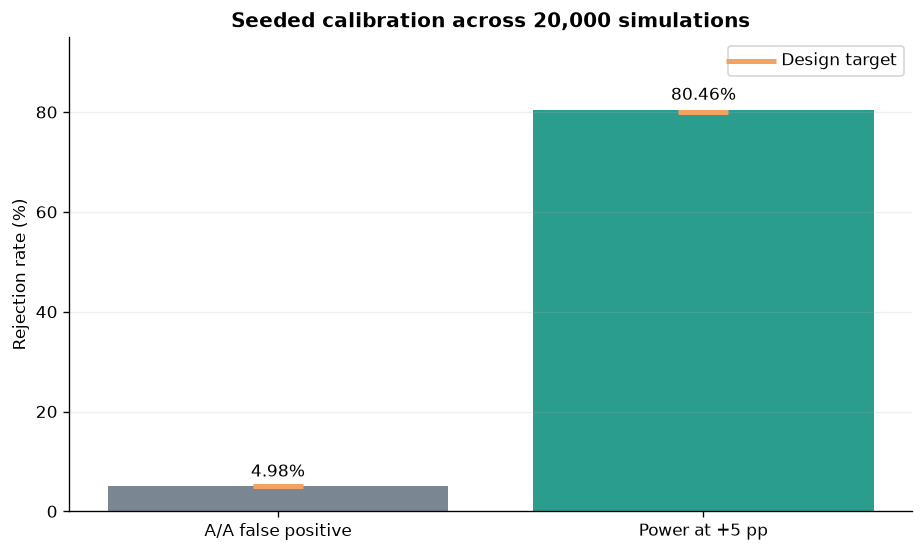

In [11]:
POWER_SIMULATION_SEED = 20_260_801
POWER_REPETITIONS = 20_000
power_rng = np.random.default_rng(POWER_SIMULATION_SEED)
critical_z = NormalDist().inv_cdf(1 - ALPHA / 2)

def simulated_rejection_rate(control_rate, treatment_rate):
    control_successes = power_rng.binomial(
        core_n_per_arm,
        control_rate,
        POWER_REPETITIONS,
    )
    treatment_successes = power_rng.binomial(
        core_n_per_arm,
        treatment_rate,
        POWER_REPETITIONS,
    )
    pooled = (
        control_successes + treatment_successes
    ) / (2 * core_n_per_arm)
    standard_error = np.sqrt(
        pooled
        * (1 - pooled)
        * (2 / core_n_per_arm)
    )
    z_statistics = (
        treatment_successes / core_n_per_arm
        - control_successes / core_n_per_arm
    ) / standard_error
    return np.mean(np.abs(z_statistics) > critical_z)

false_positive_rate = simulated_rejection_rate(
    historical_baseline_proxy,
    historical_baseline_proxy,
)
simulated_power = simulated_rejection_rate(
    historical_baseline_proxy,
    historical_baseline_proxy + PLANNED_MDE,
)
calibration = pd.DataFrame(
    [
        {
            "Scenario": "A/A: true lift = 0",
            "Rejection rate": false_positive_rate,
            "Target": ALPHA,
        },
        {
            "Scenario": "A/B: true lift = selected MDE",
            "Rejection rate": simulated_power,
            "Target": TARGET_POWER,
        },
    ]
)
calibration_display = calibration.copy()
for column in ["Rejection rate", "Target"]:
    calibration_display[column] = calibration_display[column].map(
        lambda value: f"{value:.2%}"
    )
display(calibration_display)

assert 0.035 <= false_positive_rate <= 0.065
assert 0.77 <= simulated_power <= 0.84

fig, ax = plt.subplots(figsize=(7.8, 4.7))
positions = np.arange(len(calibration))
bars = ax.bar(
    positions,
    calibration["Rejection rate"] * 100,
    color=[GREY, TEAL],
)
ax.scatter(
    positions,
    calibration["Target"] * 100,
    marker="_",
    s=900,
    linewidths=3,
    color=ORANGE,
    label="Design target",
    zorder=3,
)
ax.set_xticks(
    positions,
    ["A/A false positive", "Power at +5 pp"],
)
ax.set_ylabel("Rejection rate (%)")
ax.set_title(
    f"Seeded calibration across {POWER_REPETITIONS:,} simulations"
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
for bar, value in zip(
    bars,
    calibration["Rejection rate"] * 100,
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center",
    )
ax.set_ylim(0, 95)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "09_power_calibration.png",
    bbox_inches="tight",
)
plt.show()

## 11. Pre-registered interpretation of the simulated draw

The demonstration rule is deliberately mechanical:

1. SRM must pass.
2. The primary 95% interval must exclude zero on the positive side.
3. The point estimate must meet the provisional +5.00 pp
   minimum-worthwhile threshold.
4. The payment-error upper interval must remain below its provisional
   +1.50 pp non-inferiority margin.
5. Real telemetry and all remaining guardrails must pass before any
   launch decision.

In [12]:
simulated_primary_pass = (
    effect_lower > 0
    and effect >= PLANNED_MDE
)
simulated_demo_advance = (
    srm_pass
    and simulated_primary_pass
    and payment_guardrail_pass
)

display(
    Markdown(
        f"""
        > **SIMULATION-ONLY INTERPRETATION**
        >
        > This seeded draw estimates a {effect * 100:+.2f} pp primary
        > effect with a 95% interval of
        > {effect_lower * 100:+.2f} to
        > {effect_upper * 100:+.2f} pp.
        >
        > The demonstration rule returns
        > **{'advance to full guardrail review' if simulated_demo_advance else 'do not advance'}**.
        > This is not a real product result.
        """
    )
)

decision_checks = pd.DataFrame(
    {
        "Simulation-only check": [
            "Every row is visibly marked simulated",
            "SRM p-value is at least 0.001",
            "Primary interval lower bound is above zero",
            "Point estimate meets the provisional +5 pp threshold",
            "Payment-error upper interval is below +1.5 pp",
            "Repeated A/A false-positive rate is near 5%",
            "Repeated power at the selected MDE is near 80%",
        ],
        "Pass": [
            simulated["is_simulated"].all(),
            srm_pass,
            effect_lower > 0,
            effect >= PLANNED_MDE,
            payment_guardrail_pass,
            0.035 <= false_positive_rate <= 0.065,
            0.77 <= simulated_power <= 0.84,
        ],
    }
)
assert decision_checks["Pass"].all()
display(decision_checks)


        > **SIMULATION-ONLY INTERPRETATION**
        >
        > This seeded draw estimates a +6.80 pp primary
        > effect with a 95% interval of
        > +3.39 to
        > +10.19 pp.
        >
        > The demonstration rule returns
        > **advance to full guardrail review**.
        > This is not a real product result.
        

,Simulation-only check,Pass
0,Every row is visibly marked simulated,True
1,SRM p-value is at least 0.001,True
2,Primary interval lower bound is above zero,True
3,Point estimate meets the provisional +5 pp threshold,True
4,Payment-error upper interval is below +1.5 pp,True
5,Repeated A/A false-positive rate is near 5%,True
6,Repeated power at the selected MDE is near 80%,True


## 12. Launch gates and limitations

**Before a real experiment**

1. Implement and validate one sticky assignment/exposure signal; repeated
   `begin_checkout` events must not re-randomize or restart the window.
2. Run shadow assignment or an A/A check to measure current unique
   eligible users per day and confirm sticky exposure.
3. Obtain product and finance agreement that +5.00 pp is the smallest
   effect worth shipping.
4. Obtain payments/engineering agreement on guardrail margins.
5. Freeze the analysis plan and do not choose a new MDE after observing
   treatment outcomes.

**Limitations**

- The 48.02% baseline is session-grain and same-session, while the test
  is user-randomized with a 24-hour window.
- Historical checkout sessions overstate unique-user throughput when a
  user has multiple eligible sessions.
- The historical source records multiple `begin_checkout` events in
  92.75% of eligible sessions, so it cannot serve as assignment logging.
- The source is an obfuscated 2020–2021 sample, not current production
  traffic.
- The sample-size formula is a large-sample approximation and assumes
  independent randomized units, equal allocation, and stable rates.
- Revenue is gross rather than profit; no engineering cost or margin
  data are available.
- The favorable synthetic draw was generated under an assumed true
  +5.00 pp lift. It cannot validate the intervention.

The real experiment remains **blocked on experiment-specific telemetry
and stakeholder sign-off**, even though the statistical workflow is now
reproducible.